🚀 Iniciando análisis de ondas de choque...
Descargando datos de tráfico desde Zenodo...
Descargando coordenadas desde Zenodo...


/tmp/ipykernel_524/3751963043.py:59: RuntimeWarning: Mean of empty slice
  conges_medio = np.nanmean(conges_filtrado, axis=0)


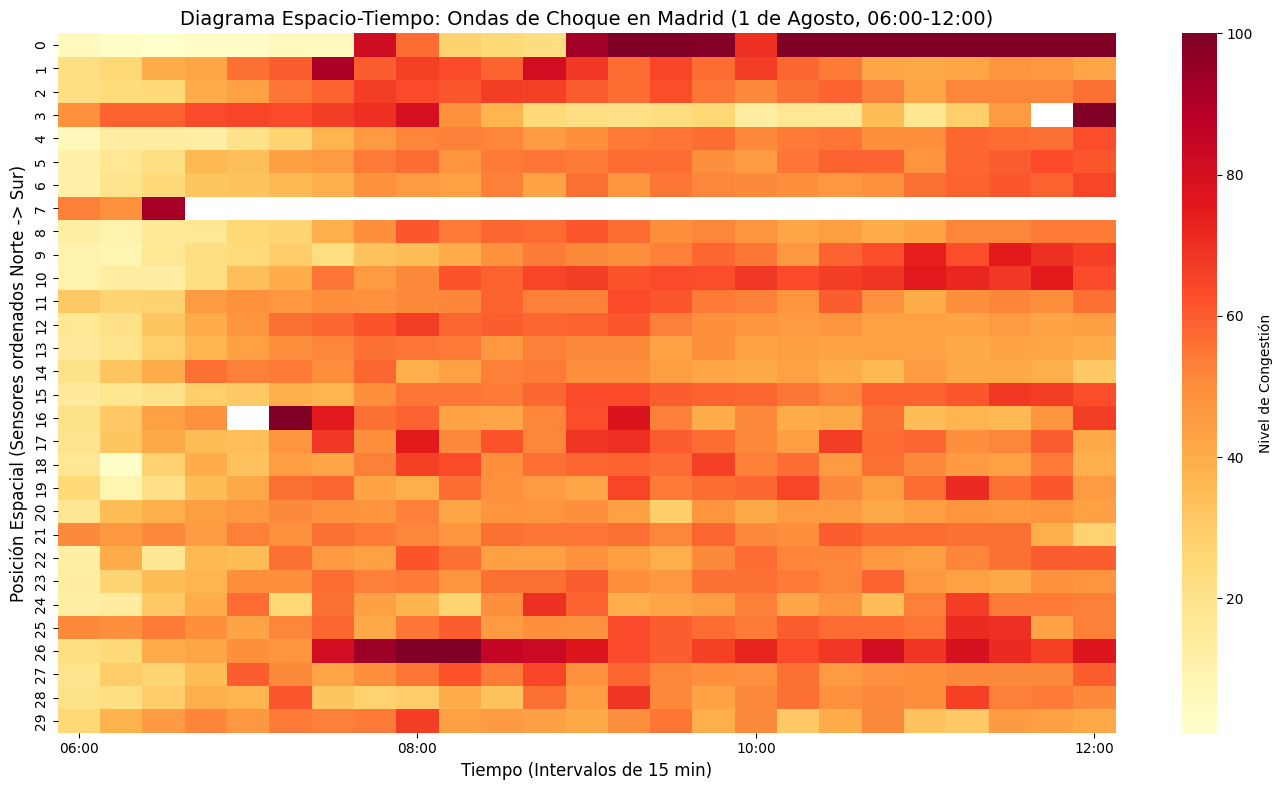

✅ Diagrama generado y guardado como 'ondas_de_choque.png'


In [1]:
# ============================================================
# ANÁLISIS DE ONDAS DE CHOQUE (SHOCKWAVE ANALYSIS)
# ============================================================
import h5py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import requests

print("🚀 Iniciando análisis de ondas de choque...")

# 1. Descargar archivos necesarios (si no están en la sesión)
ruta_trafico = "/content/fixed_sensor_data.h5"
ruta_road = "/content/road_info.h5"

if not os.path.exists(ruta_trafico):
    print("Descargando datos de tráfico desde Zenodo...")
    url = "https://zenodo.org/records/18781181/files/fixed_sensor_data.h5?download=1"
    r = requests.get(url)
    with open(ruta_trafico, 'wb') as f:
        f.write(r.content)

if not os.path.exists(ruta_road):
    print("Descargando coordenadas desde Zenodo...")
    url = "https://zenodo.org/records/18781181/files/road_info.h5?download=1"
    r = requests.get(url)
    with open(ruta_road, 'wb') as f:
        f.write(r.content)

# 2. Cargar coordenadas de los sensores
with h5py.File(ruta_road, 'r') as f:
    features = [feat.decode('utf-8') for feat in f['metadata/features'][:]]
    nodes_road = f['metadata/nodes'][:]
    vals = f['data/values'][:]
    y_coords = vals[:, features.index('y')] # Coordenada UTM Y (Norte-Sur)

df_coords = pd.DataFrame({'sensor_id': nodes_road, 'y': y_coords})

# 3. Cargar datos de tráfico y elegir un día y un corredor
with h5py.File(ruta_trafico, 'r') as f:
    features = [feat.decode('utf-8') for feat in f['metadata/features'][:]]
    nodes = f['metadata/nodes'][:]
    times = f['metadata/times'][:]
    idx_conges = features.index('conges_levl')

    # Extraer datos
    conges_data = f['data/values'][:, :, idx_conges]
    times_dt = pd.to_datetime([t.decode('utf-8') for t in times])

# Elegir un día específico (ej. 1 de agosto de 2024) en horario de mañana (6:00 a 12:00)
mask_tiempo = (times_dt >= '2024-08-01 06:00:00') & (times_dt <= '2024-08-01 12:00:00')
tiempos_filtrados = times_dt[mask_tiempo]
conges_filtrado = conges_data[mask_tiempo, :]

# 4. Seleccionar un "corredor" de sensores (Top 20 con más congestión ese día)
# Promediamos la congestión de ese día para cada sensor
conges_medio = np.nanmean(conges_filtrado, axis=0)

# Crear un DataFrame temporal para filtrar
df_temp = pd.DataFrame({'sensor_id': nodes, 'conges_medio': conges_medio})
# Unir con coordenadas
df_temp = df_temp.merge(df_coords, on='sensor_id').dropna()

# Ordenar por la coordenada Y (Norte a Sur) para crear el corredor espacial
df_corredor = df_temp.nlargest(30, 'conges_medio').sort_values(by='y', ascending=False)

# Obtener los índices de estos sensores en el array original
indices_corredor = [np.where(nodes == sid)[0][0] for sid in df_corredor['sensor_id']]

# 5. Construir la matriz Espacio-Tiempo (Sensores vs Tiempo)
# Filas: Sensores en el corredor. Columnas: Tiempo.
matriz_espacio_tiempo = conges_filtrado[:, indices_corredor].T

# 6. Visualización (El Diagrama Espacio-Tiempo)
plt.figure(figsize=(14, 8))
# Usamos un mapa de calor donde los colores oscuros indican alta congestión
sns.heatmap(matriz_espacio_tiempo, cmap='YlOrRd', cbar_kws={'label': 'Nivel de Congestión'})

plt.title('Diagrama Espacio-Tiempo: Ondas de Choque en Madrid (1 de Agosto, 06:00-12:00)', fontsize=14)
plt.xlabel('Tiempo (Intervalos de 15 min)', fontsize=12)
plt.ylabel('Posición Espacial (Sensores ordenados Norte -> Sur)', fontsize=12)

# Formatear el eje X para mostrar las horas
ticks = np.arange(0, len(tiempos_filtrados), 8) # Un tick cada 2 horas (8 * 15min)
plt.xticks(ticks + 0.5, [t.strftime('%H:%M') for t in tiempos_filtrados[ticks]], rotation=0)

plt.tight_layout()
plt.savefig('/content/ondas_de_choque.png', dpi=150)
plt.show()

print("✅ Diagrama generado y guardado como 'ondas_de_choque.png'")

El análisis de ondas de choque mediante diagramas espacio-tiempo reveló que la congestión en Madrid no es homogénea. Se identificaron dos patrones claros: 1) Una onda de propagación de tráfico que inicia en el norte a las 07:30 y desciende hacia el sur, coincidiendo con el inicio de la actividad laboral; y 2) Cuellos de botella estructurales (sensores 26-28) que presentan saturación crónica (rojo continuo) independientemente de la hora. Esto sugiere que las políticas de ajuste semafórico deben priorizar la resolución de estos nudos crónicos antes de intentar gestionar los picos de demanda.

🚀 Generando diagrama para el Domingo 4 de Agosto...


/tmp/ipykernel_524/2975129495.py:42: RuntimeWarning: Mean of empty slice
  conges_medio = np.nanmean(conges_filtrado, axis=0)


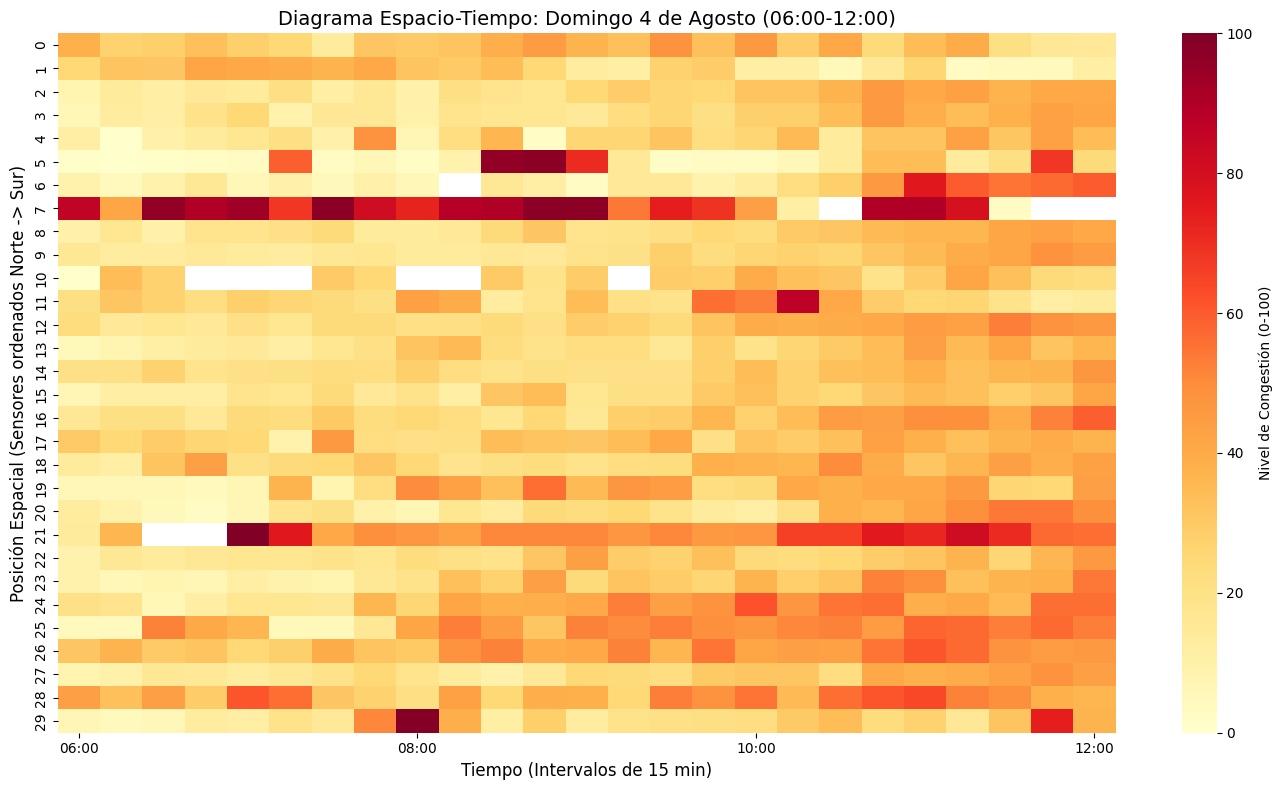

✅ Diagrama del domingo generado.


In [2]:
# ============================================================
# ANÁLISIS DE ONDAS DE CHOQUE: DOMINGO 4 DE AGOSTO
# ============================================================
import h5py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("🚀 Generando diagrama para el Domingo 4 de Agosto...")

ruta_trafico = "/content/fixed_sensor_data.h5"
ruta_road = "/content/road_info.h5"

# 1. Cargar coordenadas (Para ordenar los sensores Norte -> Sur)
with h5py.File(ruta_road, 'r') as f:
    features = [feat.decode('utf-8') for feat in f['metadata/features'][:]]
    nodes_road = f['metadata/nodes'][:]
    vals = f['data/values'][:]
    y_coords = vals[:, features.index('y')]

df_coords = pd.DataFrame({'sensor_id': nodes_road, 'y': y_coords})

# 2. Cargar datos de tráfico
with h5py.File(ruta_trafico, 'r') as f:
    features = [feat.decode('utf-8') for feat in f['metadata/features'][:]]
    nodes = f['metadata/nodes'][:]
    times = f['metadata/times'][:]
    idx_conges = features.index('conges_levl')

    conges_data = f['data/values'][:, :, idx_conges]
    times_dt = pd.to_datetime([t.decode('utf-8') for t in times])

# 3. Filtrar el Domingo 4 de Agosto (06:00 a 12:00)
mask_tiempo = (times_dt >= '2024-08-04 06:00:00') & (times_dt <= '2024-08-04 12:00:00')
tiempos_filtrados = times_dt[mask_tiempo]
conges_filtrado = conges_data[mask_tiempo, :]

# 4. Seleccionar los mismos 30 sensores más congestionados para comparar
# (Usamos el promedio del domingo para elegir el Top 30)
conges_medio = np.nanmean(conges_filtrado, axis=0)
df_temp = pd.DataFrame({'sensor_id': nodes, 'conges_medio': conges_medio})
df_temp = df_temp.merge(df_coords, on='sensor_id').dropna()
df_corredor = df_temp.nlargest(30, 'conges_medio').sort_values(by='y', ascending=False)

indices_corredor = [np.where(nodes == sid)[0][0] for sid in df_corredor['sensor_id']]

# 5. Construir la matriz Espacio-Tiempo
matriz_espacio_tiempo_dom = conges_filtrado[:, indices_corredor].T

# 6. Visualización
plt.figure(figsize=(14, 8))
# Usamos vmin=0 y vmax=100 para mantener la MISMA escala que el gráfico del jueves
sns.heatmap(matriz_espacio_tiempo_dom, cmap='YlOrRd', vmin=0, vmax=100,
            cbar_kws={'label': 'Nivel de Congestión (0-100)'})

plt.title('Diagrama Espacio-Tiempo: Domingo 4 de Agosto (06:00-12:00)', fontsize=14)
plt.xlabel('Tiempo (Intervalos de 15 min)', fontsize=12)
plt.ylabel('Posición Espacial (Sensores ordenados Norte -> Sur)', fontsize=12)

# Formatear el eje X
ticks = np.arange(0, len(tiempos_filtrados), 8)
plt.xticks(ticks + 0.5, [t.strftime('%H:%M') for t in tiempos_filtrados[ticks]], rotation=0)

plt.tight_layout()
plt.savefig('/content/ondas_de_choque_domingo.png', dpi=150)
plt.show()

print("✅ Diagrama del domingo generado.")

El análisis comparativo espacio-tiempo (Laborable vs. Domingo) demostró que la red vial de Madrid es altamente dependiente de la demanda de commuting. Mientras que el día laborable presenta una onda de propagación clara y cuellos de botella por saturación, el domingo el sistema opera casi en su totalidad en régimen de flujo libre. Sin embargo, el domingo expuso dos anomalías críticas: 1) Un fallo evidente en el sensor 7, que reportó congestión máxima durante más de 5 horas continuas (probablemente un error de telemetría); y 2) la desaparición de la congestión crónica en los sensores 26-28, demostrando que su colapso en días laborables se debe a la falta de capacidad frente a la demanda y no a un diseño deficiente de la infraestructura.